# Buổi A5: Quy trình năm bước, làm một vụ việc từ đầu đến cuối

**Hiện trường.** Chị Hạnh quyết định chạy thử trong một tháng: mỗi tuần máy đề xuất người vào diện theo dõi sát, chị duyệt lại. Nhưng chị phải trình bày với ban giám đốc, và đồng nghiệp sau này phải làm lại được đúng như chị. Vậy chị cần **một quy trình**, không chỉ một lần chạy may mắn.

**Câu hỏi của buổi này:** *một vụ việc máy học làm từ đầu đến cuối gồm những bước nào, và mỗi bước ta phải hỏi điều gì?*

Buổi này là **bài tổng hợp của Phần A**: gom mọi thứ từ A1 đến A4 thành một quy trình năm bước, rồi chạy nó một lượt.

**Mindset của người làm dữ liệu:** mô hình chỉ là *bước thứ tư trong năm bước*. Phần lớn công sức, và phần lớn sai lầm, nằm ở các bước còn lại.

**Chuẩn bị:** không cần tải file. Cú pháp từ A1 đến A4 sẽ không giải thích lại.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 0 | Nhìn toàn cảnh năm bước và chạy thử cả quy trình trong vài dòng |
| Chặng 1 | Bước 1: hỏi đúng câu hỏi, chọn thước đo, đặt mốc |
| Chặng 2 | Bước 2: khám sổ trước khi tin |
| Chặng 3 | Bước 3 và 4: chia sổ, huấn luyện cả mốc lẫn máy |
| Chặng 4 | Bước 5: đánh giá, và tìm hiểu máy sai ở đâu |
| Chặng 5 | Báo cáo cho người không học máy |

## Chặng 0: Toàn cảnh năm bước

**Câu hỏi:** quy trình năm bước trông như thế nào, và nó khớp với những gì ta đã học ra sao?

Hình dưới nối từng bước với buổi đã dạy. Chú ý mũi tên vòng ngược: kết quả ở bước 5 thường dẫn ta quay lại các bước trước.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

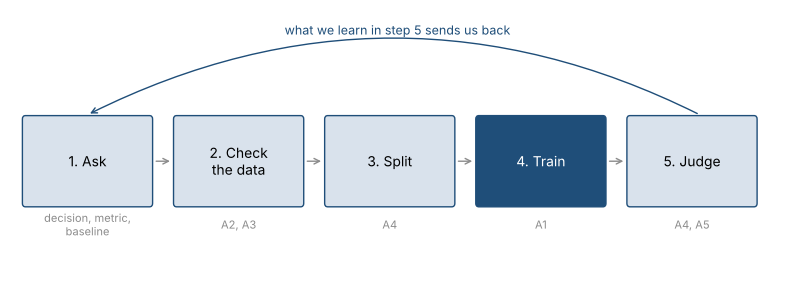

In [2]:
# Decorative diagram: just run it, no need to read the code line by line.
from matplotlib.patches import FancyBboxPatch
steps = ["1. Ask", "2. Check\nthe data", "3. Split", "4. Train", "5. Judge"]
notes = ["decision, metric,\nbaseline", "A2, A3", "A4", "A1", "A4, A5"]
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.set_xlim(0, 10); ax.set_ylim(-0.7, 2.4); ax.axis("off")
for i, (s, n) in enumerate(zip(steps, notes)):
    x = 0.2 + i * 1.95
    ax.add_patch(FancyBboxPatch((x, 0.1), 1.6, 1.0, boxstyle="round,pad=0.04", fc=BLUE if i == 3 else "#D9E2EC", ec=BLUE))
    ax.text(x + 0.8, 0.6, s, ha="center", va="center", fontsize=10, color="white" if i == 3 else "black")
    ax.text(x + 0.8, -0.15, n, ha="center", va="center", fontsize=8, color=GRAY)
    if i < 4:
        ax.annotate("", xy=(x + 1.9, 0.6), xytext=(x + 1.65, 0.6), arrowprops=dict(arrowstyle="->", color=GRAY))
ax.annotate("", xy=(1.0, 1.15), xytext=(8.9, 1.15), arrowprops=dict(arrowstyle="->", color=BLUE, connectionstyle="arc3,rad=0.25"))
ax.text(5, 2.1, "what we learn in step 5 sends us back", ha="center", fontsize=9, color=BLUE)
plt.show()

In [3]:
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
data = load_diabetes(as_frame=True, scaled=False).frame
X, y = data.drop(columns="target"), data["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LinearRegression().fit(X_train, y_train)
print("Average miss on new patients:", round((y_test - model.predict(X_test)).abs().mean(), 1))

Average miss on new patients: 42.8


**Giải thích từng dòng**

- `from ... import ... (ba dòng đầu)`: (đã học ở A1, A2, A4) lấy hàm mở dữ liệu, máy tuyến tính và hàm chia sổ.
- `data = load_diabetes(as_frame=True, scaled=False).frame`: (đã học ở A2) nạp bảng gốc.
- `X, y = data.drop(columns="target"), data["target"]`: (đã học ở A2) tách đề và đáp án **trong một dòng**: hai biểu thức cách nhau dấu phẩy, gán cho hai tên cùng lúc.
- `X_train, X_test, y_train, y_test = train_test_split(...)`: (đã học ở A4) chia 80/20 với hạt giống 42.
- `model = LinearRegression().fit(X_train, y_train)`: (đã học) học trên tập học.
- `print("Average miss on new patients:", round(..., 1))`: (đã học) in sai lệch trung bình trên tập thi. `round(số, 1)` làm tròn đến 1 chữ số thập phân.

**Cách đọc**

- **Con số:** một quy trình tối thiểu cho sai lệch khoảng 43 điểm trên bệnh nhân mới.
- **Bức tranh:** vài dòng code cho ra một kết quả, nhưng mọi quyết định quan trọng đang *nằm ngầm*: ta chọn thước đo nào, vì sao 43 là tốt hay dở, dữ liệu đã được khám chưa. Chạy được không có nghĩa là đúng quy trình.
- **Câu hỏi tiếp:** để biết 43 là tốt hay dở, ta cần cả quy trình. Bắt đầu từ bước đầu tiên, bước nhiều người bỏ qua nhất.

**Mang về chặng 0:** năm bước là *hỏi, khám dữ liệu, chia, huấn luyện, đánh giá*. Huấn luyện chỉ là bước thứ tư.

## Chặng 1: Bước 1, hỏi đúng câu hỏi

**Câu hỏi:** trước khi chạm vào dữ liệu, ta phải trả lời những gì?

Người mới thường nhảy thẳng vào code. Người làm nghề dừng lại và viết ra **hồ sơ vụ việc**:

| Mục | Với vụ của chị Hạnh |
|---|---|
| **Quyết định** | Chọn bệnh nhân vào diện theo dõi sát |
| **Ràng buộc** | Chỉ có số suất cố định mỗi tuần |
| **Thứ cần đoán** | Điểm tiến triển bệnh sau 1 năm |
| **Thước đo của máy** | Sai lệch trung bình (đơn vị: điểm) |
| **Thước đo của quyết định** | Điểm tiến triển thật trung bình của nhóm được chọn |
| **Mốc so sánh** | Đoán trung bình; chọn theo một cột đơn giản (BMI) |
| **Lằn ranh đỏ** | Máy chỉ *gợi ý*, y tá duyệt. Không dùng cho người ngoài vùng dữ liệu |

Ba mục mới nhất là **hai thước đo** và **mốc**. Thước đo của máy (sai lệch) giúp ta chỉnh mô hình. Thước đo của quyết định giúp ta biết có đáng làm không.

In [4]:
def miss(model, X, y):
    return (y - model.predict(X)).abs().mean()

def picks_score(model, X, y, k=10):
    return y.iloc[np.argsort(-model.predict(X))[:k]].mean()

**Giải thích từng dòng**

- `def miss(model, X, y): ...`: (đã học ở A2) thước đo của **máy**: sai lệch trung bình.
- `def picks_score(model, X, y, k=10): ...`: (đã học ở A4) thước đo của **quyết định**: điểm thật trung bình của `k` người máy chọn.

**Cách đọc:** hai hàm này viết xong *trước khi* xây mô hình. Việc này tưởng nhỏ nhưng rất quan trọng: nếu chọn thước đo sau khi thấy kết quả, ta sẽ vô thức chọn thước đo làm mình trông giỏi. Cố định thước đo trước là một cách tự kỷ luật.

**Mang về chặng 1:** viết ra quyết định, ràng buộc, hai thước đo, mốc so sánh và lằn ranh đỏ **trước khi** làm bất cứ thứ gì khác.

## Chặng 2: Bước 2, khám sổ trước khi tin

**Câu hỏi:** những kiểm tra nào ta phải làm mọi lần, kể cả khi dữ liệu "có vẻ sạch"?

Từ A2 và A3 ta có sẵn một túi đồ khám. Gói chúng thành một chức năng để dùng lại mọi lần, vì khám sổ là việc *lặp đi lặp lại*.

In [5]:
def checkup(X, y):
    return {
        "rows": len(X),
        "blank cells": int(X.isna().sum().sum() + y.isna().sum()),
        "duplicate rows": int(X.duplicated().sum()),
        "answer column inside X?": y.name in X.columns,
    }

checkup(X, y)

{'rows': 442,
 'blank cells': 0,
 'duplicate rows': 0,
 'answer column inside X?': False}

**Giải thích từng dòng**

- `def checkup(X, y):`: chức năng khám sổ: nhận bảng đề `X` và cột đáp án `y`.
- `return { ... }`: trả về một **từ điển** (cặp tên: giá trị) gồm bốn kết quả khám. Từ điển giúp kết quả tự mang nhãn, dễ đọc.
- `"rows": len(X)`: số dòng.
- `"blank cells": int(X.isna().sum().sum() + y.isna().sum())`: (đã học ở A2) tổng số ô trống của cả `X` lẫn `y`; `int(...)` đổi thành số nguyên cho dễ đọc.
- `"duplicate rows": int(X.duplicated().sum())`: (đã học ở A2) số dòng trùng trong `X`.
- `"answer column inside X?": y.name in X.columns`: kiểm tra rò rỉ (A2): `y.name` là **tên** của cột đáp án (ở đây là `target`), `X.columns` là danh sách tên cột của đề. Toán tử `in` hỏi *có nằm trong không*. Nếu là `True` thì đề bài đang chứa sẵn đáp án, như `X_leak` ở A2.
- `checkup(X, y)`: chạy chức năng trên đề và đáp án của ta.

In [6]:
print("Largest BMI:", data["bmi"].max(), "| smallest age:", data["age"].min())
data[["age", "bmi", "bp"]].describe().loc[["min", "max"]]

Largest BMI: 42.2 | smallest age: 19.0


,age,bmi,bp
min,19.0,18.0,62.0
max,79.0,42.2,133.0


**Giải thích từng dòng**

- `print("Largest BMI:", data["bmi"].max(), "| smallest age:", data["age"].min())`: (đã học ở A2) soi **giá trị cực đoan**: có số vô lý không?
- `data[["age", "bmi", "bp"]].describe().loc[["min", "max"]]`: `describe()` rồi `.loc[["min", "max"]]` giữ lại chỉ hai dòng `min` và `max`. Cách rẻ nhất để thấy phạm vi hợp lý của từng cột (đã học `describe` ở A2).

**Cách đọc**

- **Con số:** 442 dòng, 0 ô trống, 0 dòng trùng, đáp án không lẫn trong đề, không có số vô lý (BMI lớn nhất khoảng 42, tuổi từ 19 đến 79).
- **Bức tranh:** bản sổ gốc qua cửa khám. Nếu là cuốn sổ photo ở A2 thì ta sẽ phải dừng lại sửa trước. Điều quan trọng là **khám phải xảy ra mỗi lần** và nằm *trước* bước huấn luyện.
- **Vì sao gói thành chức năng:** vì người sau (đồng nghiệp của chị Hạnh) chỉ việc gọi `checkup(...)` thay vì nhớ lại từng kiểm tra. Quy trình tốt là quy trình mà người khác làm lại được.

**Mang về chặng 2:** gói các kiểm tra dữ liệu thành một chức năng dùng lại. Khám trước, huấn luyện sau.

## Chặng 3: Bước 3 và 4, chia sổ, huấn luyện cả mốc lẫn máy

**Câu hỏi:** ta cần huấn luyện những ai để so sánh công bằng?

Sổ đã chia ở chặng 0. Giờ cho **ba người chơi** học cùng tập học:

1. **Mốc lười:** luôn đoán trung bình của tập học.
2. **Máy đơn giản:** chỉ nhìn một cột BMI (như A1).
3. **Máy đủ cột:** nhìn cả 10 cột.

In [7]:
from sklearn.dummy import DummyRegressor
lazy = DummyRegressor(strategy="mean").fit(X_train, y_train)
simple = LinearRegression().fit(X_train[["bmi"]], y_train)
full = model

**Giải thích từng dòng**

- `from sklearn.dummy import DummyRegressor`: lấy máy "giả" của sklearn, chuyên dùng làm mốc.
- `lazy = DummyRegressor(strategy="mean").fit(X_train, y_train)`: `DummyRegressor` luôn đoán một con số cố định. `strategy="mean"` nghĩa là con số đó là **trung bình của đáp án tập học**. Nó nhận cả bảng `X_train` nhưng bỏ qua hoàn toàn, chỉ lấy `y_train` để tính trung bình. Đây là phiên bản chính thức của "mốc lười" ta tự viết ở A1.
- `simple = LinearRegression().fit(X_train[["bmi"]], y_train)`: máy chỉ nhìn một cột. Hai cặp ngoặc vuông để `X` vẫn là bảng.
- `full = model`: đặt thêm tên `full` cho máy đủ 10 cột đã học ở chặng 0, để ba tên `lazy`, `simple`, `full` ngang hàng.

**Cách đọc:** có ba người chơi, từ đơn giản nhất đến đầy đủ nhất. Mỗi người chỉ hơn người trước nếu thực sự đáng. Nếu máy đủ cột không hơn máy đơn giản thì thêm 9 cột là phí công và thêm rủi ro.

**Mang về chặng 3:** luôn huấn luyện cả mốc lẫn máy trên **cùng một tập học**, để so công bằng.

## Chặng 4: Bước 5, đánh giá, và tìm hiểu máy sai ở đâu

**Câu hỏi:** ba người chơi chênh nhau thế nào, bằng cả hai thước đo?

In [8]:
players = {"lazy": (lazy, X_test), "simple": (simple, X_test[["bmi"]]), "full": (full, X_test)}
rows = []
for name, (m, X_part) in players.items():
    rows.append({"player": name, "miss (points)": round(miss(m, X_part, y_test), 1),
                 "avg score of 10 picks": round(picks_score(m, X_part, y_test), 0)})
pd.DataFrame(rows)

,player,miss (points),avg score of 10 picks
0,lazy,64.0,162.0
1,simple,52.3,200.0
2,full,42.8,256.0


**Giải thích từng dòng**

- `players = {"lazy": (lazy, X_test), ...}`: từ điển ba người chơi; mỗi giá trị là **cặp** (máy, bảng đề của máy đó). Cặp là hai thứ đặt trong ngoặc tròn, vì máy đơn giản chỉ nhận cột BMI.
- `for name, (m, X_part) in players.items():`: lặp qua từng người chơi. Phần `(m, X_part)` **tách luôn cặp** thành hai tên ngay trong dòng `for`.
- `rows.append({"player": name, "miss (points)": ..., "avg score of 10 picks": ...})`: (đã học ở A2) ghi một dòng kết quả với hai thước đo. Mốc lười đoán cùng một số cho mọi người nên khi xếp hạng nó chọn **10 người đầu tiên** do không phân biệt được ai, một cách chọn gần như ngẫu nhiên.
- `pd.DataFrame(rows)`: đổi thành bảng.

**Cách đọc**

- **Con số:** sai lệch lần lượt khoảng 64 (mốc lười), 52 (máy một cột), 43 (máy đủ cột). Điểm của 10 người được chọn: mốc lười khoảng 162 (nó đoán mọi người bằng nhau nên chỉ lấy 10 người đầu danh sách, gần như ngẫu nhiên; trung bình cả tập thi là 146), máy một cột khoảng 201, máy đủ cột khoảng 256, mức trần khoảng 277.
- **Bức tranh:** mỗi lần thêm thông tin, máy đều tốt hơn ở **cả hai thước đo**. Đây là bằng chứng để chị Hạnh dùng máy đủ cột thay vì chỉ nhìn BMI. Nếu máy đủ cột *không* hơn máy một cột thì ta nên dùng máy một cột cho đơn giản.
- **Một điều thành thật:** tập thi chỉ có 89 người nên các con số dao động theo cách chia (A4). Mình đã thử 30 cách chia khác nhau: máy đủ cột có sai lệch thấp hơn máy một cột ở **cả 30**, và chọn được nhóm nặng hơn ở **26 trong 30**. Cho nên kết luận "đủ cột hơn một cột" đáng tin, còn chênh lệch cụ thể trong từng lần chia thì ồn.

Điều chị Hạnh cần biết thêm: máy sai ở **kiểu người nào**?

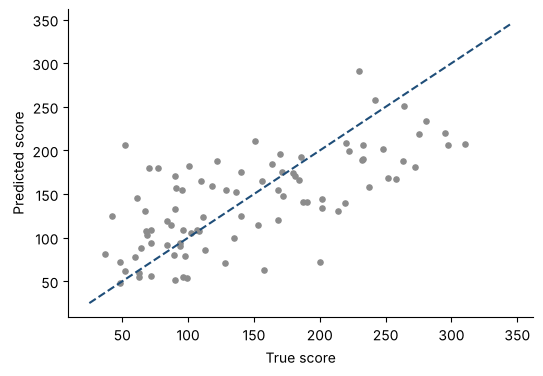

In [9]:
pred = full.predict(X_test)
plt.scatter(y_test, pred, s=14, color=GRAY)
plt.plot([y.min(), y.max()], [y.min(), y.max()], "--", color=BLUE)
plt.xlabel("True score"); plt.ylabel("Predicted score")
plt.show()

**Giải thích từng dòng**

- `pred = full.predict(X_test)`: dự đoán cho tập thi.
- `plt.scatter(y_test, pred, s=14, color=GRAY)`: mỗi chấm là một bệnh nhân thi: hoành độ là điểm thật, tung độ là điểm máy đoán.
- `plt.plot([y.min(), y.max()], [y.min(), y.max()], "--", color=BLUE)`: đường chéo nét đứt: nơi đoán **trùng** thật. Chấm nằm trên đường là đoán đúng, nằm dưới đường là máy đoán **thấp hơn** thật.
- `plt.xlabel(...); plt.ylabel(...); plt.show()`: ghi tên trục và hiện hình.

**Cách đọc**

- **Con số:** hầu hết chấm nằm quanh đường chéo, nhưng đám mây rộng cỡ vài chục điểm.
- **Bức tranh:** ở **phía phải** (người thật sự nặng, điểm trên 250), các chấm nằm **dưới** đường chéo: máy đoán thấp hơn thật. Ở **phía trái** (người nhẹ), các chấm hơi cao hơn đường. Máy có xu hướng *kéo mọi dự đoán về giữa*, dè dặt với ca cực đoan.
- **Hệ quả cho quyết định:** đúng ở chỗ chị Hạnh cần nhất (ca nặng) máy lại đoán thấp nhất. Điều này không làm máy vô dụng, vì thứ chị cần là *xếp hạng* chứ không cần đoán đúng số, nhưng chị phải biết để không tin số tuyệt đối mà máy đưa ra cho ca nặng.

In [10]:
error = y_test - pred
top_fifth = y_test > y_test.quantile(0.8)
print(f"Typical patients: average error {error[~top_fifth].mean():+.0f}")
print(f"Heaviest 20%    : average error {error[top_fifth].mean():+.0f}  (positive = machine guessed too low)")

Typical patients: average error -8
Heaviest 20%    : average error +50  (positive = machine guessed too low)


**Giải thích từng dòng**

- `error = y_test - pred`: sai số **có dấu**: thật trừ đoán. Dương nghĩa là máy đoán thấp hơn thật.
- `top_fifth = y_test > y_test.quantile(0.8)`: `quantile(0.8)` là mốc mà 80% bệnh nhân thấp hơn; `y_test > mốc` đánh dấu Đúng cho **20% người nặng nhất**.
- `error[~top_fifth].mean()`: `~` là **đảo** Đúng/Sai: ở đây chọn 80% còn lại. Rồi lấy trung bình sai số của nhóm đó.
- `error[top_fifth].mean()`: trung bình sai số của nhóm 20% nặng nhất.
- `:+.0f`: định dạng số nguyên **luôn kèm dấu** cộng hoặc trừ.

**Cách đọc:** với đa số bệnh nhân, sai số trung bình chỉ khoảng -8 (hơi đoán cao, nhưng nhỏ), nhưng với 20% nặng nhất, máy đoán thấp hơn thật khoảng **50 điểm** trung bình. Đây gọi là **sai số có hệ thống**, nguy hiểm hơn sai số ngẫu nhiên vì nó luôn lệch cùng một hướng ở đúng nhóm quan trọng.

**Mang về chặng 4:** đánh giá bằng cả hai thước đo, so với mốc, rồi **mổ xẻ chỗ sai**. Con số trung bình tốt vẫn có thể che một nhóm bị đoán tệ có hệ thống.

## Chặng 5: Báo cáo cho người không học máy

**Câu hỏi:** ban giám đốc không cần biết `LinearRegression`. Họ cần biết gì?

Một báo cáo tốt trả lời bốn câu: *làm gì, hơn cách đơn giản bao nhiêu, sai ở đâu, nên làm gì.* Ta để chương trình tự điền con số vào mẫu, để mọi lần chạy đều ra báo cáo nhất quán.

In [11]:
random_pick = y_test.mean()
full_pick = picks_score(full, X_test, y_test)
print(f"1. Mỗi tuần máy gợi ý 10 người cần theo dõi sát.")
print(f"2. Nhóm máy chọn có điểm tiến triển trung bình {full_pick:.0f}, so với {random_pick:.0f} nếu chọn ngẫu nhiên.")
print(f"3. Máy đoán thấp hơn thật khoảng {error[top_fifth].mean():.0f} điểm ở nhóm nặng nhất: chỉ dùng để xếp hạng, không dùng số tuyệt đối.")
print("4. Khuyến nghị: chạy thử một tháng, y tá duyệt lại danh sách, đo lại bằng ca mới.")

1. Mỗi tuần máy gợi ý 10 người cần theo dõi sát.
2. Nhóm máy chọn có điểm tiến triển trung bình 256, so với 146 nếu chọn ngẫu nhiên.
3. Máy đoán thấp hơn thật khoảng 50 điểm ở nhóm nặng nhất: chỉ dùng để xếp hạng, không dùng số tuyệt đối.
4. Khuyến nghị: chạy thử một tháng, y tá duyệt lại danh sách, đo lại bằng ca mới.


**Giải thích từng dòng**

- `random_pick = y_test.mean()`: điểm trung bình của cả tập thi: nếu chọn ngẫu nhiên thì kỳ vọng nhóm được chọn có điểm bằng mức này.
- `full_pick = picks_score(full, X_test, y_test)`: điểm nhóm chọn của máy đủ cột.
- `print(f"1. ...")`: bốn dòng báo cáo, mỗi dòng một ý. Trong dòng 2 và 3, con số được **nhúng tự động** bằng f-string; đổi dữ liệu hay hạt giống thì báo cáo tự cập nhật, không cần sửa tay. (Báo cáo viết bằng tiếng Việt vì người đọc là ban giám đốc; phần mã vẫn tiếng Anh.)

## Phán quyết và bài học nghề

**Phán quyết.**

- **Con số:** máy đủ cột chọn nhóm có điểm trung bình khoảng 256, so với 146 (ngẫu nhiên) và 201 (chỉ nhìn BMI); mức trần khoảng 277.
- **Khuyến nghị:** chạy thử một tháng với máy đủ cột, y tá duyệt danh sách. Nhớ rằng máy đoán thấp ở ca nặng nhất, nên không dùng số tuyệt đối để quyết định liều chăm sóc.
- **Việc cần làm tiếp:** thử cải thiện máy (thêm đường cong, xử lý quá khớp) ở **Phần B**, và thử nhiều bài toán khác (đoán nhóm thay vì đoán số) ở **A6** và **Phần C**.

**Bài học nghề.**

1. **Hỏi trước, code sau.** Hai thước đo và mốc phải viết ra trước khi xây mô hình.
2. **Khám dữ liệu là việc lặp lại, hãy gói thành chức năng.**
3. **Luôn có mốc.** Con số 43 tự nó không có nghĩa; nó chỉ có nghĩa khi đặt cạnh 64 và 52.
4. **Mổ xẻ chỗ sai.** Điểm trung bình tốt có thể che một nhóm bị đoán tệ có hệ thống, và đó thường là nhóm quan trọng nhất.
5. **Người khác phải làm lại được.** Hạt giống cố định, chức năng dùng lại, báo cáo tự điền.

**Một điều thành thật:** quy trình này đã chạy trên một lần chia và một bộ 442 ca. Trước khi tin dùng thật, ta cần dữ liệu mới theo thời gian (bệnh nhân tháng sau), vì máy học từ quá khứ và tương lai có thể khác.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 0 | Năm bước: hỏi, khám dữ liệu, chia, huấn luyện, đánh giá. Huấn luyện chỉ là bước thứ tư. |
| 1 | Viết hồ sơ vụ việc: quyết định, ràng buộc, hai thước đo, mốc, lằn ranh đỏ, trước khi làm gì khác. |
| 2 | Gói các kiểm tra dữ liệu thành một chức năng dùng lại. |
| 3 | Huấn luyện cả mốc lẫn máy trên cùng tập học. |
| 4 | Đánh giá bằng hai thước đo, so với mốc, rồi mổ xẻ chỗ máy sai có hệ thống. |
| 5 | Báo cáo bằng ngôn ngữ quyết định, tự điền con số để nhất quán. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Hồ sơ vụ việc | định nghĩa bài toán (problem framing) | bảng ở chặng 1 |
| Cách đoán lười để làm mốc | mốc cơ sở (baseline) | `DummyRegressor` |
| Thước đo của máy / của quyết định | metric kỹ thuật / metric nghiệp vụ | `miss`, `picks_score` |
| Khám sổ trước khi tin | kiểm tra chất lượng dữ liệu | `checkup(data)` |
| Máy luôn lệch một hướng ở nhóm nặng | sai số có hệ thống (bias) | `error[top_fifth].mean()` |
| Chạy thử một tháng có người duyệt | triển khai thử (pilot) | bước 5 của quy trình |

**Thử thách tự làm**

1. Đổi số người chọn `k` từ 10 thành 5 rồi 20 ở chặng 4 (đổi giá trị mặc định trong `picks_score`). Máy đủ cột còn hơn máy một cột ở cả hai mức không? (Gợi ý: tập thi chỉ có 89 người, `k=20` là hơn 20% số đó.)
2. Đổi `random_state=42` ở chặng 0 thành 7 rồi chạy lại toàn bộ. Thứ tự ba người chơi có đổi không, con số báo cáo thay đổi ra sao? (Gợi ý: nhớ chạy lại từ ô đầu tiên của chặng 0.)
3. Thêm một người chơi thứ tư: máy nhìn ba cột `bmi`, `bp`, `s5`. Nó nằm ở đâu giữa máy một cột và máy đủ cột? (Gợi ý: thêm vào từ điển `players` với bảng `X_test[["bmi", "bp", "s5"]]` và nhớ huấn luyện bằng đúng ba cột đó.)

**Checklist năng lực** (tự tick khi làm được)

- [ ] Kể đủ năm bước và nối từng bước với buổi đã học.
- [ ] Viết được hồ sơ vụ việc: quyết định, hai thước đo, mốc, lằn ranh đỏ.
- [ ] Gói được các kiểm tra dữ liệu thành một chức năng.
- [ ] So được máy với mốc bằng cả hai thước đo.
- [ ] Tìm và nêu được một chỗ máy sai có hệ thống.
- [ ] Viết được báo cáo bốn câu bằng ngôn ngữ quyết định.

## Phần thưởng (Tip pro): Bảng điểm có sai số: một con số không đủ


Trong chặng 4, mình đã thử 30 cách chia để biết kết luận có vững không. Đó là một thói quen quý: **mọi so sánh quan trọng nên chạy lại với vài hạt giống khác nhau**. Ở phần D, kiểm định chéo làm việc này một cách bài bản. Còn bây giờ, chạy ô dưới để tự thấy máy đủ cột thắng máy một cột ở bao nhiêu trong 30 cách chia.

In [12]:
wins = 0
for seed in range(30):
    a, b, c, d = train_test_split(X, y, test_size=0.2, random_state=seed)
    one = LinearRegression().fit(a[["bmi"]], c)
    ten = LinearRegression().fit(a, c)
    wins += miss(ten, b, d) < miss(one, b[["bmi"]], d)
print(f"Full model beats the one-column model in {wins} of 30 splits")

Full model beats the one-column model in 30 of 30 splits


**Giải thích từng dòng**

- `wins = 0`: biến đếm, bắt đầu từ 0.
- `for seed in range(30):`: (đã học ở A4) thử 30 hạt giống.
- `a, b, c, d = train_test_split(...)`: (đã học ở A4) chia sổ theo hạt giống hiện tại.
- `one = LinearRegression().fit(a[["bmi"]], c)`: máy một cột học trên tập học mới.
- `ten = LinearRegression().fit(a, c)`: máy mười cột học trên cùng tập học.
- `wins += miss(ten, b, d) < miss(one, b[["bmi"]], d)`: `+=` nghĩa là **cộng thêm vào biến đang có**. Vế phải là phép so sánh cho Đúng hoặc Sai; Đúng được tính là 1 khi cộng. Vậy mỗi lần máy mười cột sai lệch thấp hơn, `wins` tăng 1.
- `print(f"Full model beats ... in {wins} of 30 splits")`: in kết quả.